# CA1 - Data Visualisation and Communication 

## Cover Page

Lecturer Name: Taufique Ahmed 
### Barbara Souza 2023059
### GitHub Link
https://github.com/BarbSouza/data-visualisation.git
### Video Link
https://drive.google.com/drive/folders/19yAy5wb7vKj4OV-kTpZ81bX17kZqhXc9?usp=drive_link 

## Imports

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import plotly.express as px

## Loding dataset and field descriptions

In [2]:
dataset =  pd.read_excel("all_data_M_2023.xlsx")

In [3]:
dataset_description = pd.read_excel("all_data_M_2023.xlsx", sheet_name="Field Descriptions")

In [4]:
pd.set_option("display.max_colwidth", None)
dataset_description

,May 2023 OEWS Estimates,Unnamed: 1,Unnamed: 2
0,NaN,NaN,NaN
1,Occupational Employment and Wage Statistics (OEWS) Survey,NaN,NaN
2,"Bureau of Labor Statistics, Department of Labor",NaN,NaN
3,website: www.bls.gov/oes,NaN,NaN
4,email: oewsinfo@bls.gov,NaN,NaN
5,NaN,NaN,NaN
6,Not all fields are available for every type of estimate,NaN,NaN
7,NaN,NaN,NaN
8,Field,Field Description,NaN
9,area,"U.S. (99), state FIPS code, Metropolitan Statistical Area (MSA) or New England City and Town Area (NECTA) code, or OEWS-specific nonmetropolitan area code",NaN


## Dataset info

In [5]:
dataset.head(10)

,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,00-0000,All Occupations,...,23.11,37.01,58.4,29050,35660,48060,76980,121470,NaN,NaN
1,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-0000,Management Occupations,...,56.19,81.29,111.36,54550,78330,116880,169090,231620,NaN,NaN
2,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1000,Top Executives,...,49.74,79.57,#,46400,66170,103460,165500,#,NaN,NaN
3,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1010,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN
4,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1011,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN
5,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1020,General and Operations Managers,...,48.69,77.06,111.59,46340,65180,101280,160290,232110,NaN,NaN
6,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1021,General and Operations Managers,...,48.69,77.06,111.59,46340,65180,101280,160290,232110,NaN,NaN
7,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1030,Legislators,...,*,*,*,21010,28810,47290,82200,129510,True,NaN
8,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1031,Legislators,...,*,*,*,21010,28810,47290,82200,129510,True,NaN
9,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-2000,"Advertising, Marketing, Promotions, Public Relations, and Sales Managers",...,67.23,96.15,#,69170,99180,139850,199990,#,NaN,NaN


In [6]:
dataset.shape

(413327, 32)

rows (occupation) x columns (information)

In [7]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 413327 entries, 0 to 413326
Data columns (total 32 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   AREA          413327 non-null  int64 
 1   AREA_TITLE    413327 non-null  object
 2   AREA_TYPE     413327 non-null  int64 
 3   PRIM_STATE    413327 non-null  object
 4   NAICS         413327 non-null  object
 5   NAICS_TITLE   413327 non-null  object
 6   I_GROUP       413327 non-null  object
 7   OWN_CODE      413327 non-null  int64 
 8   OCC_CODE      413327 non-null  object
 9   OCC_TITLE     413327 non-null  object
 10  O_GROUP       413327 non-null  object
 11  TOT_EMP       413327 non-null  object
 12  EMP_PRSE      413327 non-null  object
 13  JOBS_1000     235826 non-null  object
 14  LOC_QUOTIENT  235826 non-null  object
 15  PCT_TOTAL     170470 non-null  object
 16  PCT_RPT       170470 non-null  object
 17  H_MEAN        413327 non-null  object
 18  A_MEAN        413327 non

Only AREA, AREA_TYPE and OWN_CODE are numeric
That should be fixed so in the charts all information can be counted and visualised, the reason they are text is because a few cells contain symbols.

In [8]:
dataset.isnull().sum()

AREA                 0
AREA_TITLE           0
AREA_TYPE            0
PRIM_STATE           0
NAICS                0
NAICS_TITLE          0
I_GROUP              0
OWN_CODE             0
OCC_CODE             0
OCC_TITLE            0
O_GROUP              0
TOT_EMP              0
EMP_PRSE             0
JOBS_1000       177501
LOC_QUOTIENT    177501
PCT_TOTAL       242857
PCT_RPT         242857
H_MEAN               0
A_MEAN               0
MEAN_PRSE            0
H_PCT10              0
H_PCT25              0
H_MEDIAN             0
H_PCT75              0
H_PCT90              0
A_PCT10              0
A_PCT25              0
A_MEDIAN             0
A_PCT75              0
A_PCT90              0
ANNUAL          396830
HOURLY          412572
dtype: int64

Jobs_1000 and LOC_QuOITIENT exists only for state and metropolitan area rows
pct_Total and PCT_RPT are empty because they only exist for national industry rows
ANNUAL and Hourly are almost entirely empty becaus they are only filled for unusual occupations.

In [9]:
dataset.describe()

,AREA,AREA_TYPE,OWN_CODE
count,4.133270e+05,413327.000000,413327.000000
mean,3.784693e+05,2.766826,717.279984
std,1.135906e+06,1.780825,601.852382
min,1.000000e+00,1.000000,1.000000
25%,9.900000e+01,1.000000,5.000000
50%,9.900000e+01,2.000000,1235.000000
75%,3.710000e+04,4.000000,1235.000000
max,7.800001e+06,6.000000,1235.000000


Only shows the code columns so the avarages are not meaninful

In [10]:
dataset.value_counts("AREA_TYPE")

AREA_TYPE
1    177501
4    149591
6     48559
2     36643
3      1033
Name: count, dtype: int64

rows per kind of area
- 1 - Whole US
- 2 - states
- 3 - territories
- 4 - metropolitan
- 6 - non-metropolitan

In [11]:
dataset.value_counts("I_GROUP")

I_GROUP
cross-industry               237229
4-digit                       83350
3-digit                       39097
sector                        16376
5-digit                       15518
4-digit, ownership             9856
cross-industry, ownership      5628
3-digit, ownership             4561
6-digit                        1712
Name: count, dtype: int64

rows per industry level

In [12]:
dataset.value_counts("O_GROUP")

O_GROUP
detailed    306185
broad        62131
minor        23374
major        20601
total         1036
Name: count, dtype: int64

rows per occupation level

In [13]:
dataset.value_counts("OWN_CODE")

OWN_CODE
1235    237229
5       144246
235       8465
2         6419
3         6076
57        3689
123       3538
1         1878
58         960
59         827
Name: count, dtype: int64

rows per ownership type

In [14]:
dataset.value_counts("TOT_EMP")

TOT_EMP
40           19325
50           16872
60           14450
70           12537
**           11598
             ...  
151853870        1
130039030        1
22068580         1
21814850         1
18533450         1
Name: count, Length: 12271, dtype: int64

how often each employment figure appears

In [15]:
dataset.value_counts("A_MEDIAN")

A_MEDIAN
*         5083
#         2391
41600      618
31200      584
52000      572
          ... 
237780       1
236650       1
236920       1
238120       1
238160       1
Name: count, Length: 16664, dtype: int64

Change the * to no information and # 239,200 per year

Need to seperate the rows so the same ocuppation don't get count more than once

## Cleaning

In [16]:
clean = dataset.copy()

In [17]:
for col in ["A_MEDIAN", "TOT_EMP", "A_MEAN", "A_PCT10", "A_PCT25", "A_PCT75", "A_PCT90"]:
    clean[col] = clean[col].replace("#", 239200)
    clean[col] = pd.to_numeric(clean[col], errors="coerce")

In [18]:
clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 413327 entries, 0 to 413326
Data columns (total 32 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   AREA          413327 non-null  int64  
 1   AREA_TITLE    413327 non-null  object 
 2   AREA_TYPE     413327 non-null  int64  
 3   PRIM_STATE    413327 non-null  object 
 4   NAICS         413327 non-null  object 
 5   NAICS_TITLE   413327 non-null  object 
 6   I_GROUP       413327 non-null  object 
 7   OWN_CODE      413327 non-null  int64  
 8   OCC_CODE      413327 non-null  object 
 9   OCC_TITLE     413327 non-null  object 
 10  O_GROUP       413327 non-null  object 
 11  TOT_EMP       401729 non-null  float64
 12  EMP_PRSE      413327 non-null  object 
 13  JOBS_1000     235826 non-null  object 
 14  LOC_QUOTIENT  235826 non-null  object 
 15  PCT_TOTAL     170470 non-null  object 
 16  PCT_RPT       170470 non-null  object 
 17  H_MEAN        413327 non-null  object 
 18  A_ME

In [19]:
clean["TOT_EMP"].isnull().sum()

np.int64(11598)

In [20]:
clean["A_MEDIAN"].isnull().sum()

np.int64(5083)

In [21]:
clean.describe()

,AREA,AREA_TYPE,OWN_CODE,TOT_EMP,A_MEAN,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90
count,4.133270e+05,413327.000000,413327.000000,4.017290e+05,4.082440e+05,408244.000000,408244.000000,408244.000000,408244.000000,408244.000000
mean,3.784693e+05,2.766826,717.279984,1.275895e+04,6.810923e+04,42905.108367,51510.702203,63460.996610,78346.608425,94751.161242
std,1.135906e+06,1.780825,601.852382,3.608032e+05,3.866052e+04,20248.761249,26227.641535,33782.605405,41967.481657,50381.550438
min,1.000000e+00,1.000000,1.000000,3.000000e+01,1.675000e+04,15080.000000,15080.000000,15080.000000,16670.000000,16950.000000
25%,9.900000e+01,1.000000,5.000000,1.000000e+02,4.321000e+04,30350.000000,35110.000000,40160.000000,48110.000000,58010.000000
50%,9.900000e+01,2.000000,1235.000000,3.200000e+02,5.734000e+04,37440.000000,44630.000000,53430.000000,65530.000000,79530.000000
75%,3.710000e+04,4.000000,1235.000000,1.530000e+03,8.143000e+04,49250.000000,60890.000000,76970.000000,96990.000000,119500.000000
max,7.800001e+06,6.000000,1235.000000,1.518539e+08,1.805790e+06,239200.000000,239200.000000,239200.000000,239200.000000,239200.000000


In [22]:
national=clean.loc[(clean['AREA_TYPE'] == 1) & (clean["I_GROUP"] == "cross-industry") & (clean["O_GROUP"] == "detailed") & (clean["OCC_CODE"].str.startswith("15-"))]
national.head()

,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
135,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,15-1211,Computer Systems Analysts,...,49.9,63.74,79.66,63230.0,80380.0,103800.0,132580.0,165700.0,NaN,NaN
136,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,15-1212,Information Security Analysts,...,57.87,73.82,87.68,69210.0,90050.0,120360.0,153550.0,182370.0,NaN,NaN
138,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,15-1221,Computer and Information Research Scientists,...,69.75,89.02,112.07,81450.0,109990.0,145080.0,185160.0,233110.0,NaN,NaN
140,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,15-1231,Computer Network Support Specialists,...,34.39,44.5,58.61,45660.0,54700.0,71530.0,92570.0,121920.0,NaN,NaN
141,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,15-1232,Computer User Support Specialists,...,28.48,36.52,46.65,37690.0,46550.0,59240.0,75950.0,97020.0,NaN,NaN


In [23]:
national.shape

(21, 32)

In [24]:
state=clean.loc[(clean['AREA_TYPE'] == 2) & (clean["O_GROUP"] == "detailed") & (clean["OCC_CODE"].str.startswith("15-"))]
state.head()

,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
181042,1,Alabama,2,AL,000000,Cross-industry,cross-industry,1235,15-1211,Computer Systems Analysts,...,49.31,63.6,80.35,63980.0,79490.0,102560.0,132280.0,167130.0,NaN,NaN
181043,2,Alaska,2,AK,000000,Cross-industry,cross-industry,1235,15-1211,Computer Systems Analysts,...,41.69,52.63,61.11,50620.0,61180.0,86720.0,109460.0,127110.0,NaN,NaN
181044,4,Arizona,2,AZ,000000,Cross-industry,cross-industry,1235,15-1211,Computer Systems Analysts,...,48.21,61.57,69.07,49170.0,69100.0,100280.0,128070.0,143660.0,NaN,NaN
181045,5,Arkansas,2,AR,000000,Cross-industry,cross-industry,1235,15-1211,Computer Systems Analysts,...,37.12,47.44,61.55,54040.0,60900.0,77210.0,98670.0,128020.0,NaN,NaN
181046,6,California,2,CA,000000,Cross-industry,cross-industry,1235,15-1211,Computer Systems Analysts,...,59.79,75.56,89.16,75520.0,96750.0,124370.0,157170.0,185460.0,NaN,NaN


In [25]:
state.shape

(973, 32)

In [26]:
industry=clean.loc[(clean['AREA_TYPE'] == 1) & (clean["I_GROUP"] == "sector") & (clean["O_GROUP"] == "detailed") & (clean["OCC_CODE"].str.startswith("15-"))]
industry.head()

,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
2850,99,U.S.,1,US,11,"Agriculture, Forestry, Fishing and Hunting",sector,5,15-1211,Computer Systems Analysts,...,45.41,62.55,86.27,65570.0,72210.0,94450.0,130110.0,179440.0,NaN,NaN
2852,99,U.S.,1,US,11,"Agriculture, Forestry, Fishing and Hunting",sector,5,15-1232,Computer User Support Specialists,...,33.96,39.48,49.19,46140.0,51110.0,70640.0,82120.0,102320.0,NaN,NaN
2854,99,U.S.,1,US,11,"Agriculture, Forestry, Fishing and Hunting",sector,5,15-1244,Network and Computer Systems Administrators,...,42.36,52.08,65.02,51970.0,73790.0,88120.0,108320.0,135250.0,NaN,NaN
2856,99,U.S.,1,US,11,"Agriculture, Forestry, Fishing and Hunting",sector,5,15-1252,Software Developers,...,60.81,67.92,77.97,67600.0,102340.0,126490.0,141280.0,162170.0,NaN,NaN
2858,99,U.S.,1,US,11,"Agriculture, Forestry, Fishing and Hunting",sector,5,15-1299,"Computer Occupations, All Other",...,41.57,60.91,63.5,55610.0,58540.0,86470.0,126690.0,132080.0,NaN,NaN


In [27]:
industry.shape

(357, 32)

## Visualisation 1 - Bar Chart
- **Objective:** Compare which industries employ the most Data Scientists
- **Visualisation type:** To compare numbers(employees) across categories(Industry), Horizontal because labels are long

In [44]:
data_scientists["NAICS_TITLE"].unique()

array(['Accommodation and Food Services',
       'Mining, Quarrying, and Oil and Gas Extraction', 'Construction',
       'Arts, Entertainment, and Recreation', 'Utilities',
       'Real Estate and Rental and Leasing',
       'Transportation and Warehousing', 'Retail Trade',
       'Other Services (except Public Administration)', 'Government',
       'Wholesale Trade', 'Educational Services', 'Manufacturing',
       'Health Care and Social Assistance',
       'Administrative and Support and Waste Management and Remediation Services',
       'Management of Companies and Enterprises', 'Information',
       'Finance and Insurance',
       'Professional, Scientific, and Technical Services'], dtype=object)

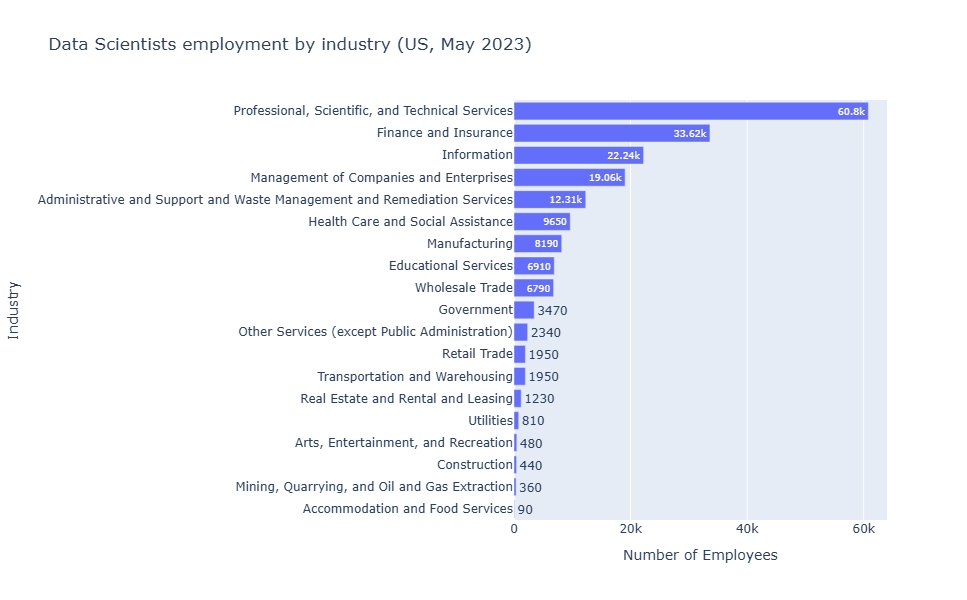

In [51]:
industry_emp = industry.sort_values(by="TOT_EMP")
data_scientists = industry_emp.loc[(industry_emp['OCC_TITLE'] == "Data Scientists")].copy()
#The industry name was taking too much space so I shortned
data_scientists["NAICS_TITLE"] = data_scientists["NAICS_TITLE"].replace({"Federal, State, and Local Government, excluding State and Local Government Schools and Hospitals and the U.S. Postal Service (OEWS Designation)": "Government"})
fig = px.bar(
    data_scientists,
    x="TOT_EMP",
    y="NAICS_TITLE",
    orientation="h",
    title="Data Scientists employment by industry (US, May 2023)",
    labels={"TOT_EMP": "Number of Employees", "NAICS_TITLE":"Industry"},
    height=600,
    text_auto=True
)
fig.show()

In [50]:
total = data_scientists["TOT_EMP"].sum()
top_one = data_scientists["TOT_EMP"].max()
top_three = data_scientists["TOT_EMP"].nlargest(3).sum()
print("Top industry share:", round(top_one / total * 100, 1), "%")
print("Top three industry share:", round(top_three / total * 100, 1), "%")

Top industry share: 31.6 %
Top three industry share: 60.5 %


- **What I learned:** Data scientists are more found in industries such as Professional, Scientific, and Technical Services (60,800) and less in Accommodation and Food Services (90). This suggests the industries whose business rely more on information of data will need more Data Scientists.

## Visualisation 2 - Histogram
- **Objective:** Investigate how Software Developers median pay is distributed across the 51 states
- **Visualisation type:** The histogram to show how a numeric value (median pay) is distributed across the states showing how concentrated or spread out they are.

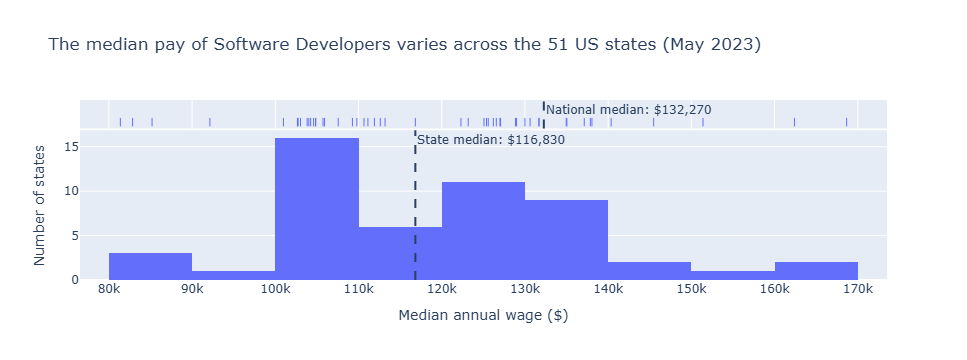

In [102]:
software_states = state.loc[(state['OCC_TITLE'] == "Software Developers")]
national_median_software = national.loc[national['OCC_TITLE'] == "Software Developers", "A_MEDIAN"].iloc[0]
state_median_software = state.loc[state['OCC_TITLE'] == "Software Developers", "A_MEDIAN"].median()
fig_hist = px.histogram(
    software_states,
    x = 'A_MEDIAN',
    nbins = 10,
    title = 'The median pay of Software Developers varies across the 51 US states (May 2023)',
    labels = {"A_MEDIAN" : "Median annual wage ($)", "count": "Number of states"},
    marginal="rug",
    hover_name="AREA_TITLE"
)
fig_hist.add_vline(x=national_median_software, line_dash="dash", row=2, col=1,annotation_text=f"National median: ${national_median_software:,.0f}")
fig_hist.add_vline(x=state_median_software, line_dash="dash", row=1, col=1, annotation_text=f"State median: ${state_median_software:,.0f}")
fig_hist.update_layout(yaxis_title="Number of states")
fig_hist.show()

- **What I learned:** The median pay across the 51 states in the US for Software Developers varies from `$81,380` in West Virginia being the lowest to `$168,660` in California being the highest paying state. The most common range between states is between `$100,000` and `$110,000` with 16 states. This suggests that the Software Developers can earn more or less depending on which state they work on. 42 of the 51 states fall between `$100,000` and `$140,000`. The median across states is `$116,830`

In [68]:
software_states.sort_values(by="A_MEDIAN")[["AREA_TITLE", "A_MEDIAN"]]

,AREA_TITLE,A_MEDIAN
181590,West Virginia,81380.0
181583,South Dakota,82850.0
181566,Mississippi,85190.0
181545,Arkansas,92140.0
181576,North Dakota,100980.0
181591,Wisconsin,102660.0
181554,Idaho,102700.0
181542,Alabama,102730.0
181559,Kentucky,103030.0
181564,Michigan,103830.0


## Visualisation 3
1. What is the **objective** of the visualisation? (eg investigation, comparison etc)
2. **Why that visualisation type was chosen**? (categorical, numerical, relationships).  
3. **What you learned** about AI employment from the visualisation.  

## Visualisation 4
1. What is the **objective** of the visualisation? (eg investigation, comparison etc)
2. **Why that visualisation type was chosen**? (categorical, numerical, relationships).  
3. **What you learned** about AI employment from the visualisation.  

## Visualisation 5
1. What is the **objective** of the visualisation? (eg investigation, comparison etc)
2. **Why that visualisation type was chosen**? (categorical, numerical, relationships).  
3. **What you learned** about AI employment from the visualisation.  

## Challenge
1. What is the **objective** of the visualisation? (eg investigation, comparison etc)
2. **Why that visualisation type was chosen**? (categorical, numerical, relationships).  
3. **What you learned** about AI employment from the visualisation.  

# References:
